In [1]:
import glob, os
# glob finds files by name and os asks the operator the file size
import pandas as pd
# pandas is the tool
import matplotlib.pyplot as plt
# matplotlib.pyplot is the tool for charts

print(pd.__version__)


3.0.3


In [2]:
files = sorted(glob.glob("fuzzing_data_*.csv"))
#this will call for the files with the name "fuzzing_data" and that ends with .csv, * calls for all the files with the different numbers
# sorted puts it all in order


In [3]:
print(len(files), "files found")
# len(files) counts how many names are in the list and prints it out

18 files found


In [4]:
rows = []
# creates an empty list 
for f in files:
# takes every file and holds it in f
    size_mb = round(os.path.getsize(f) / 1e6, 1)
#returns the files in bytes and devides it into megabytes where it keeps it with 1 decimal place
    with open(f, "r", encoding="utf-8", errors="ignore") as fh:
        row_count = sum(1 for _ in fh) - 1
    #with tells the program that the file can close when the indented lines are done
    # error = "ignore" makes the program to skip any odd characters instead of crashing it.
    cols = pd.read_csv(f, nrows=0).columns.tolist()
    rows.append({"file": f, "size_mb": size_mb, "rows": row_count, "columns": len(cols)})
inventory = pd.DataFrame(rows)
inventory
    #turns the list into a table with one row per file

,file,size_mb,rows,columns
0,fuzzing_data_01.csv,2.6,15610,20
1,fuzzing_data_02.csv,297.4,1312754,20
2,fuzzing_data_03.csv,143.9,770747,20
3,fuzzing_data_04.csv,20.4,111516,20
4,fuzzing_data_05.csv,1462.1,6139223,20
5,fuzzing_data_06.csv,6.8,40735,20
6,fuzzing_data_07.csv,548.9,2246448,20
7,fuzzing_data_08.csv,488.8,2071484,20
8,fuzzing_data_09.csv,464.0,1983255,20
9,fuzzing_data_10.csv,424.6,1843815,20


In [5]:
first_cols = pd.read_csv(files[0], nrows=0).columns.tolist()

for f in files:
     cols = pd.read_csv(f, nrows=0).columns.tolist()
     print(f, "matches file 01" if cols == first_cols else "DIFFERENT columns")

fuzzing_data_01.csv matches file 01
fuzzing_data_02.csv matches file 01
fuzzing_data_03.csv matches file 01
fuzzing_data_04.csv matches file 01
fuzzing_data_05.csv DIFFERENT columns
fuzzing_data_06.csv matches file 01
fuzzing_data_07.csv DIFFERENT columns
fuzzing_data_08.csv DIFFERENT columns
fuzzing_data_09.csv DIFFERENT columns
fuzzing_data_10.csv DIFFERENT columns
fuzzing_data_11.csv matches file 01
fuzzing_data_12.csv matches file 01
fuzzing_data_13.csv matches file 01
fuzzing_data_14.csv matches file 01
fuzzing_data_15.csv matches file 01
fuzzing_data_16.csv matches file 01
fuzzing_data_17.csv matches file 01
fuzzing_data_18.csv matches file 01


In [6]:
summary = []                                   # one entry per file
for f in files:
    d = pd.read_csv(f, low_memory=False)                         # load one file
    summary.append({
        "file": f,
        "rows": len(d),
        "duplicate_rows": d.duplicated().sum(),
        "label_1": (d["label"] == 1).sum(),
        "tag_changes": (d["tag_changed"].astype(str) == "True").sum(),
        "status_values": sorted(d["plc_status"].astype(str).unique().tolist()),
    })
    del d                                      # free the memory before the next file

summary_df = pd.DataFrame(summary)
summary_df["duplicate_share"] = (summary_df["duplicate_rows"] / summary_df["rows"]).round(3)
summary_df

,file,rows,duplicate_rows,label_1,tag_changes,status_values,duplicate_share
0,fuzzing_data_01.csv,15610,11720,3174,44,"[Error, Triggered]",0.751
1,fuzzing_data_02.csv,1312754,1226116,439975,5319,[0],0.934
2,fuzzing_data_03.csv,770747,703104,294784,6374,"[Error, Triggered, Unknown]",0.912
3,fuzzing_data_04.csv,111516,83808,32366,541,"[Error, Triggered]",0.752
4,fuzzing_data_05.csv,6139223,6077137,3186264,43532,[6031],0.990
5,fuzzing_data_06.csv,40735,35545,7694,232,"[Error, Triggered, Unknown]",0.873
6,fuzzing_data_07.csv,2246448,2215290,1265432,14708,[6031],0.986
7,fuzzing_data_08.csv,2071484,2040320,1049587,13938,[6031],0.985
8,fuzzing_data_09.csv,1983255,1952099,970753,14490,[6031],0.984
9,fuzzing_data_10.csv,1843815,1812664,847615,14596,[6031],0.983


In [7]:
ref = pd.read_csv(files[0], nrows=0).columns.tolist()    # file 01's columns
odd = ["fuzzing_data_05.csv", "fuzzing_data_07.csv", "fuzzing_data_08.csv",
       "fuzzing_data_09.csv", "fuzzing_data_10.csv"]

for f in odd:
    cols = pd.read_csv(f, nrows=0).columns.tolist()
    print(f)
    print("  only in this file:", [c for c in cols if c not in ref])
    print("  only in file 01:  ", [c for c in ref if c not in cols])
    print("  same names, different order:", set(cols) == set(ref) and cols != ref)

fuzzing_data_05.csv
  only in this file: ['recursion_level']
  only in file 01:   ['is_tag']
  same names, different order: False
fuzzing_data_07.csv
  only in this file: ['recursion_level']
  only in file 01:   ['is_tag']
  same names, different order: False
fuzzing_data_08.csv
  only in this file: ['recursion_level']
  only in file 01:   ['is_tag']
  same names, different order: False
fuzzing_data_09.csv
  only in this file: ['recursion_level']
  only in file 01:   ['is_tag']
  same names, different order: False
fuzzing_data_10.csv
  only in this file: ['recursion_level']
  only in file 01:   ['is_tag']
  same names, different order: False


In [8]:
total_rows = summary_df["rows"].sum()
total_dups = summary_df["duplicate_rows"].sum()

print(total_rows, total_dups)
print(round(total_dups / total_rows, 3))
print(total_rows - total_dups)
print(total_dups)

18588041 17922610
0.964
665431
17922610


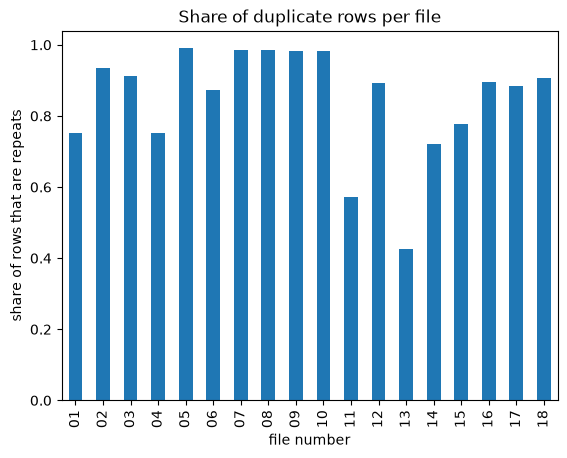

In [9]:
summary_df["file_num"] = summary_df["file"].str[-6:-4]    # pull "01", "02"... out of the file name

summary_df.plot(x="file_num", y="duplicate_share", kind="bar", legend=False,
                title="Share of duplicate rows per file")
plt.xlabel("file number")
plt.ylabel("share of rows that are repeats")
plt.show()